# Проект "Развлекательное приложение"

## Описание проекта

В этом проекте будут использованы данные компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В этом приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

## Цели и задачи проекта

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Необходимо рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

Задачи, поставленные в проекте:
- Рассчитать параметры теста
- Оценить корректность его проведения
- Проанализировать результаты эксперимента

## Описание данных

В ходе проекта будем работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## План работы

- Работа с историческими данными (EDA)
- Подготовка к тесту
- Мониторинг А/В-теста¶
- Проверка результатов A/B-теста

## 1. Работа с историческими данными (EDA)

### 1.1 Загрузка исторических данных

In [1]:
# Импортируем библиотеки для анализа данных
import pandas as pd
from math import ceil

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеки для проверки гипотез
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# Загружаем датафрейм
sessions_history = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_history.csv')

### 1.2 Знакомство с данными

In [3]:
# Познакомимся с содержанием таблицы sessions_history
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


In [4]:
# Выводим информацию о датафрейме
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            435924 non-null  object
 1   session_id         435924 non-null  object
 2   session_date       435924 non-null  object
 3   session_start_ts   435924 non-null  object
 4   install_date       435924 non-null  object
 5   session_number     435924 non-null  int64 
 6   registration_flag  435924 non-null  int64 
 7   page_counter       435924 non-null  int64 
 8   region             435924 non-null  object
 9   device             435924 non-null  object
dtypes: int64(3), object(7)
memory usage: 33.3+ MB


In [5]:
# Для каждого уникального пользователя user_id рассчитаем количество уникальных сессий session_id
top_user = (
    sessions_history
    .groupby('user_id', as_index=False)['session_id']
    .nunique()
    .rename(columns={'session_id': 'sessions_count'})
    .sort_values('sessions_count', ascending=False)
    .iloc[0]  # берём первого (пользователя с максимальным числом сессий)
)

In [6]:
# Выведем на экран все данные из таблицы sessions_history для одного пользователя с наибольшим количеством сессий и изучим
top_user_data = sessions_history[sessions_history['user_id'] == top_user['user_id']]
top_user_data

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


Теперь мы лучше понимаем логику формирования каждого столбца данных

### 1.3 Анализ числа регистраций

Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируем, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, нам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU, но для регистраций пользователей).

In [7]:
# Агрегируем данные
agg_reg = (
    sessions_history
    .groupby('session_date', as_index=False)
    .agg(
        total_users=('user_id', 'nunique'),      
        registered_users=('registration_flag', 'sum') 
    )
)

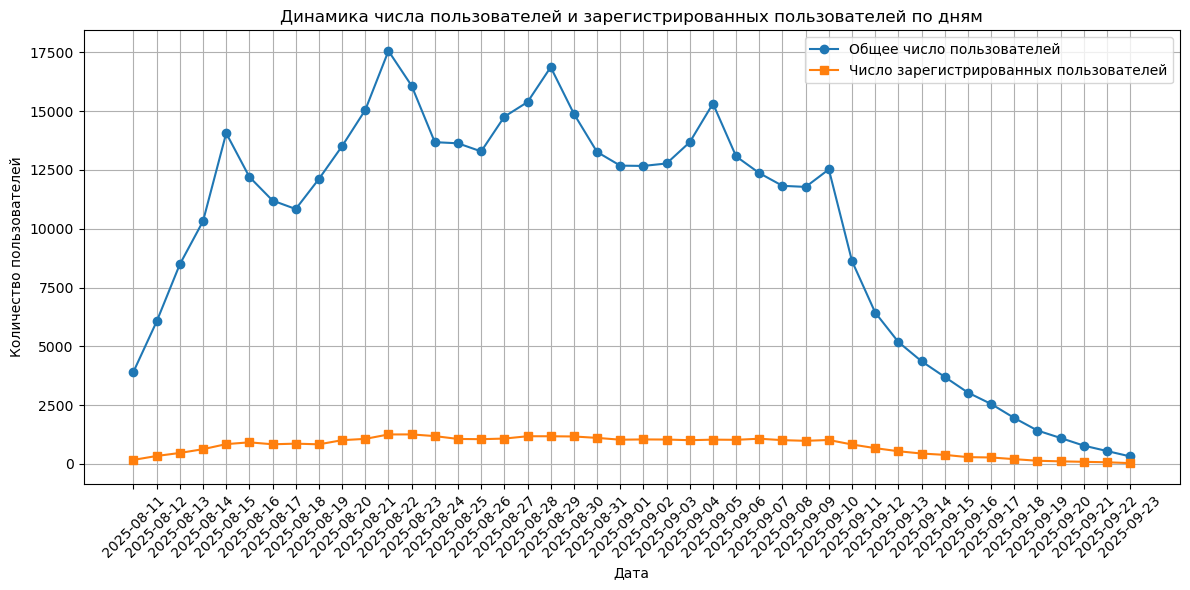

In [8]:
# Строим линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням
plt.figure(figsize=(12, 6))
plt.plot(agg_reg['session_date'], agg_reg['total_users'], label='Общее число пользователей', marker='o')
plt.plot(agg_reg['session_date'], agg_reg['registered_users'], label='Число зарегистрированных пользователей', marker='s')

plt.title('Динамика числа пользователей и зарегистрированных пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Выводы:
- В период 2025‑08‑11 — 2025‑09‑06 общее число пользователей демонстрировало волатильный рост с пиками до ~17 500;
- С 2025‑09‑07 наблюдается устойчивый тренд на снижение общего числа пользователей (до ~500 к 2025‑09‑23);
- Число зарегистрированных пользователей оставалось относительно стабильным на уровне ~1 000–1 500 до 2025‑09‑10, затем снизилось до ~500;
- Соотношение зарегистрированных к общему числу пользователей выросло с ~10–15% в начале периода до ~25–30% в конце — вероятно, за счёт оттока незарегистрированных пользователей;
- Резкое падение после 2025‑09‑06 может указывать на завершение маркетинговой кампании, технический сбой либо изменение алгоритмов рекомендаций.

In [9]:
# Рассчитываем долю зарегистрированных пользователей
agg_reg['registered_share'] = agg_reg['registered_users'] / agg_reg['total_users']

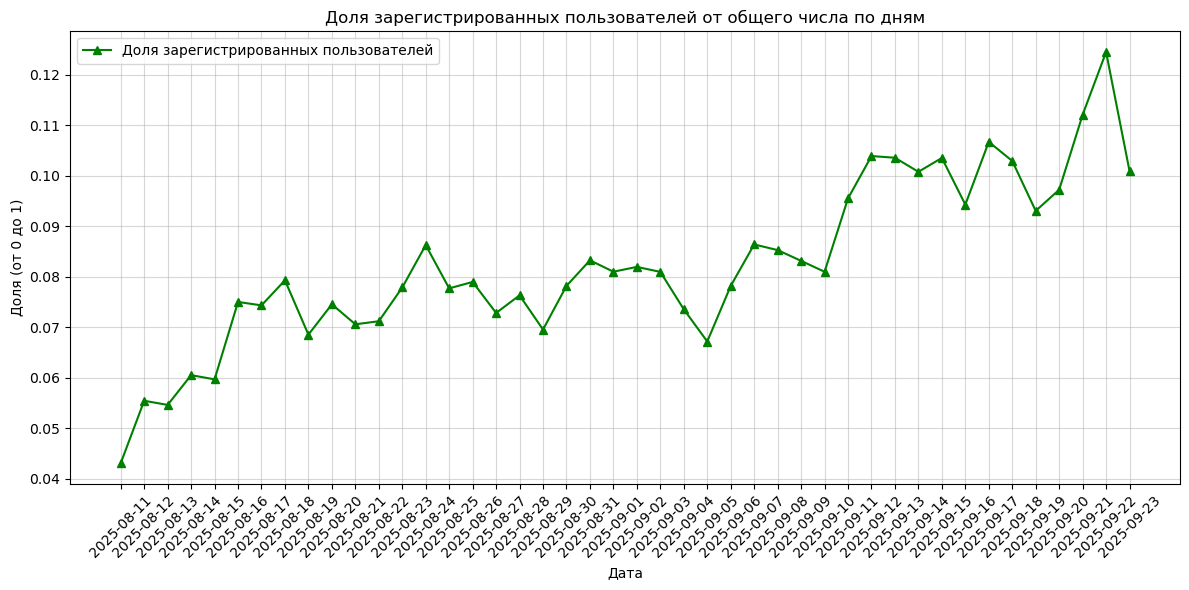

In [10]:
# Строим линейный график доли зарегистрированных пользователей
plt.figure(figsize=(12, 6))
plt.plot(agg_reg['session_date'], agg_reg['registered_share'], color='green', label='Доля зарегистрированных пользователей', marker='^')

plt.title('Доля зарегистрированных пользователей от общего числа по дням')
plt.xlabel('Дата')
plt.ylabel('Доля (от 0 до 1)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Выводы:
- Доля зарегистрированных пользователей стабильно росла с 0.043 (11.08.2025) до 0.085–0.088 (конец августа), затем — до 0.103–0.105 (09–13.09.2025);
- 21.09.2025 зафиксирован пик доли — 0.123, далее — снижение до 0.101 (23.09.2025);
- Волатильность показателя в сентябре выше, чем в августе;
- Рост доли может отражать эффективность онбординга/промо‑акций либо отток незарегистрированных пользователей;
- Резкий всплеск 21.09.2025 — вероятный эффект точечной кампании, реферальной механики либо технического сбоя учёта.

### 1.4. Анализ числа просмотренных страниц

Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

Проанализируем число просмотренных страниц во время первых сессий пользователей. Найдем количество первых сессий для каждого значения количества просмотренных страниц.

In [11]:
# Фильтруем только первые сессии
first_sessions = sessions_history[sessions_history['session_number'] == 1]

In [12]:
# Считаем число первых сессий для каждого значения количества просмотренных страниц
page_dist = (
    first_sessions
    .groupby('page_counter', as_index=False)
    .size()
    .rename(columns={'size': 'first_sessions_count'})
    .sort_values('page_counter')
)

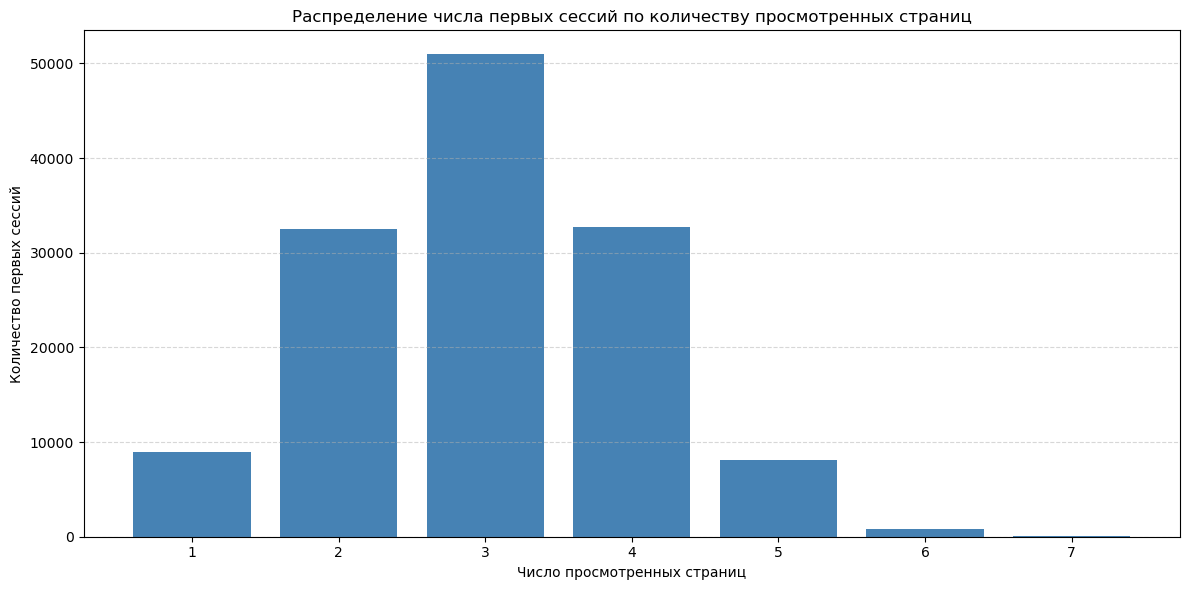

In [13]:
# Строим столбчатую диаграмму
plt.figure(figsize=(12, 6))
plt.bar(page_dist['page_counter'], page_dist['first_sessions_count'], color='steelblue')

plt.title('Распределение числа первых сессий по количеству просмотренных страниц')
plt.xlabel('Число просмотренных страниц')
plt.ylabel('Количество первых сессий')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Выводы:
- Пик распределения — 3 просмотренные страницы (≈51 000 первых сессий);
- Высокая доля сессий с 2–4 страницами (суммарно ≈115 000 сессий, ~75% от общего объёма);
- Резкое снижение числа сессий при ≥5 страниц: 5 страниц — ≈8 000, 6–7 страниц — <2 000;
- Большинство новых пользователей ограничиваются 2–4 страницами — зона потенциального роста вовлечённости;
- Малая доля глубоких сессий (≥5 страниц) сигнализирует о необходимости оптимизации удержания на ранних этапах просмотра.

### 1.5. Доля пользователей, просмотревших более четырёх страниц

Продуктовая команда продукта считает, что первые сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

Создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше. Затем 

In [14]:
# Создаем столбец good_session
sessions_history['good_session'] = (sessions_history['page_counter'] >= 4).astype(int)

In [15]:
# Отбираем только первые сессии
first_sessions = sessions_history[sessions_history['session_number'] == 1].copy()

In [16]:
# Считаем количество успешных первых сессий по дням
daily_stats = (
    first_sessions
    .groupby('session_date', as_index=False)
    .agg(
        total_first_sessions=('user_id', 'size'),          # всего первых сессий
        good_first_sessions=('good_session', 'sum')        # успешных первых сессий
    )
)

# Считаем долю успешных первых сессий по дням
daily_stats['success_rate'] = daily_stats['good_first_sessions'] / daily_stats['total_first_sessions']

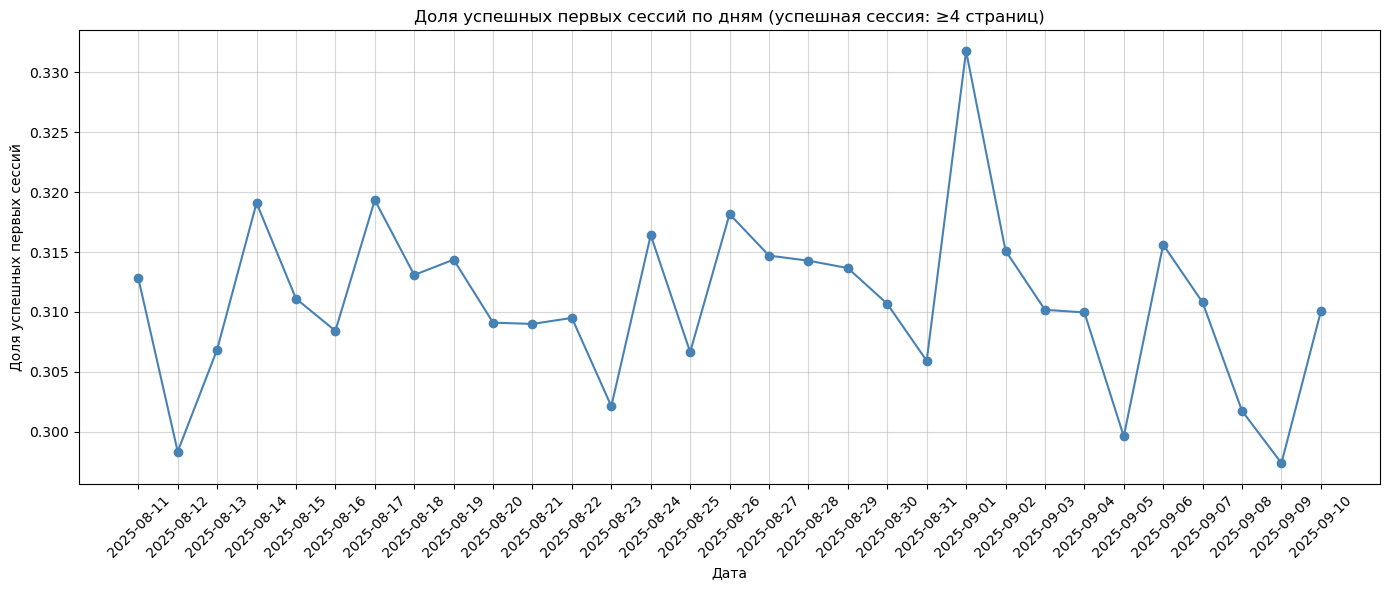

In [17]:
# Строим график доли успешных первых сессий по дням
plt.figure(figsize=(14, 6))
plt.plot(daily_stats['session_date'], daily_stats['success_rate'], marker='o', linestyle='-', color='steelblue')

plt.title('Доля успешных первых сессий по дням (успешная сессия: ≥4 страниц)')
plt.xlabel('Дата')
plt.ylabel('Доля успешных первых сессий')
plt.grid(True, alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Выводы:
- Диапазон доли успешных сессий: 0.299–0.330;
- Пик 0.330 зафиксирован 2025‑09‑01 — максимальный уровень вовлечённости за период;
- Минимумы 0.299 отмечены 2025‑08‑12, 2025‑09‑09 — критические точки падения удержания;
- Волатильность показателя сохраняется на всём интервале (амплитуда ~0.031), выраженные колебания каждые 3–5 дней;
- Тренд отсутствует: чередование подъёмов и спадов без устойчивого роста/снижения;
- Резкий всплеск 2025‑09‑01 может быть связан с запуском контента/акции либо изменением алгоритмов рекомендаций.

## 2. Подготовка к тесту

### 2.1. Расчёт размера выборки

Для расчета необходимого размера выборки используем метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

In [18]:
# Задайте параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.009  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


### 2.2. Расчёт длительности A/B-теста

Используя данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения, рассчитаем длительность теста, разделив одно на другое.

In [19]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = (
    sessions_history
    .groupby('session_date')['user_id']
    .nunique()
    .mean()
)

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil((sample_size * 2) / avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {round(avg_daily_users)} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907 пользователей в день составит 9 дней


## 3. Мониторинг А/В-теста

### 3.1. Проверка распределения пользователей

На данном этапе A/B-тест успешно запущен, и уже доступны данные за первые три дня. Теперь нужно убедиться, что все идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются. В частности рассчитаем количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

In [20]:
# Загружаем датафрейм с частичными результатами теста
sessions_test_part = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_test_part.csv')

In [21]:
# Выделяем один день наблюдения
test_date = sessions_test_part['session_date'].min()

In [22]:
# Уникальные пользователи в каждой группе за один день наблюдения
users_per_group = (
    sessions_test_part[sessions_test_part['session_date'] == test_date]
    .groupby('test_group')['user_id']
    .nunique()
)

print(f'Дата наблюдения: {test_date}')
print('Количество уникальных пользователей в группах:')
print(users_per_group)

Дата наблюдения: 2025-10-14
Количество уникальных пользователей в группах:
test_group
A    1477
B    1466
Name: user_id, dtype: int64


In [23]:
# Процентная разница между группами A и B
a_users = users_per_group['A']
b_users = users_per_group['B']
p = 100 * abs(a_users - b_users) / a_users

print(f'Процентная разница в количестве пользователей групп A и B: {p:.2f}%')

Процентная разница в количестве пользователей групп A и B: 0.74%


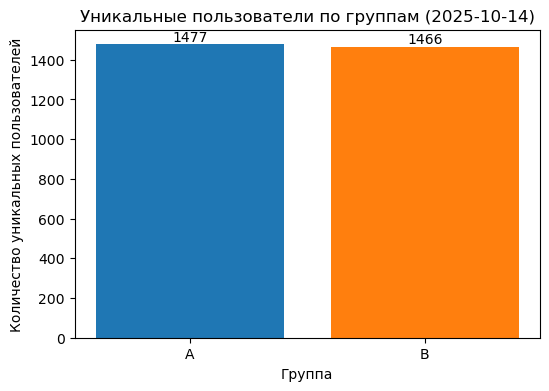

In [24]:
plt.figure(figsize=(6, 4))
bars = plt.bar(users_per_group.index, users_per_group.values,
               color=['tab:blue', 'tab:orange'])

# Подписываем значения над столбцами вручную
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height,
              f'{int(height)}', ha='center', va='bottom')

plt.title(f'Уникальные пользователи по группам ({test_date})')
plt.xlabel('Группа')
plt.ylabel('Количество уникальных пользователей')
plt.show()

Как мы видим, пользователи распределены по тестовым группам равномерно.

### 3.2. Проверка пересечений пользователей

Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

In [25]:
# Разделение пользователей по группам
users_A = set(sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id'])
users_B = set(sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id'])

# Пересечение множеств (пользователи, присутствующие в обеих группах)
users_in_both = users_A & users_B

# Вывод результатов
print(f"Количество уникальных пользователей в группе A: {len(users_A)}")
print(f"Количество уникальных пользователей в группе B: {len(users_B)}")
print(f"Количество пользователей, встречающихся в обеих группах: {len(users_in_both)}")

Количество уникальных пользователей в группе A: 1477
Количество уникальных пользователей в группе B: 1466
Количество пользователей, встречающихся в обеих группах: 0


Пересечений между группами нет.

### 3.3. Равномерность разделения пользователей по устройствам

Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

In [26]:
# Фильтруем данные по одному дню
day_data = sessions_test_part[sessions_test_part['session_date'] == test_date]

# Считаем уникальных пользователей по каждому устройству в каждой группе
device_counts = (
    day_data
    .groupby(['test_group', 'device'])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

# Переводим в % внутри каждой группы
device_share_a = device_counts.loc['A'] / device_counts.loc['A'].sum() * 100
device_share_b = device_counts.loc['B'] / device_counts.loc['B'].sum() * 100

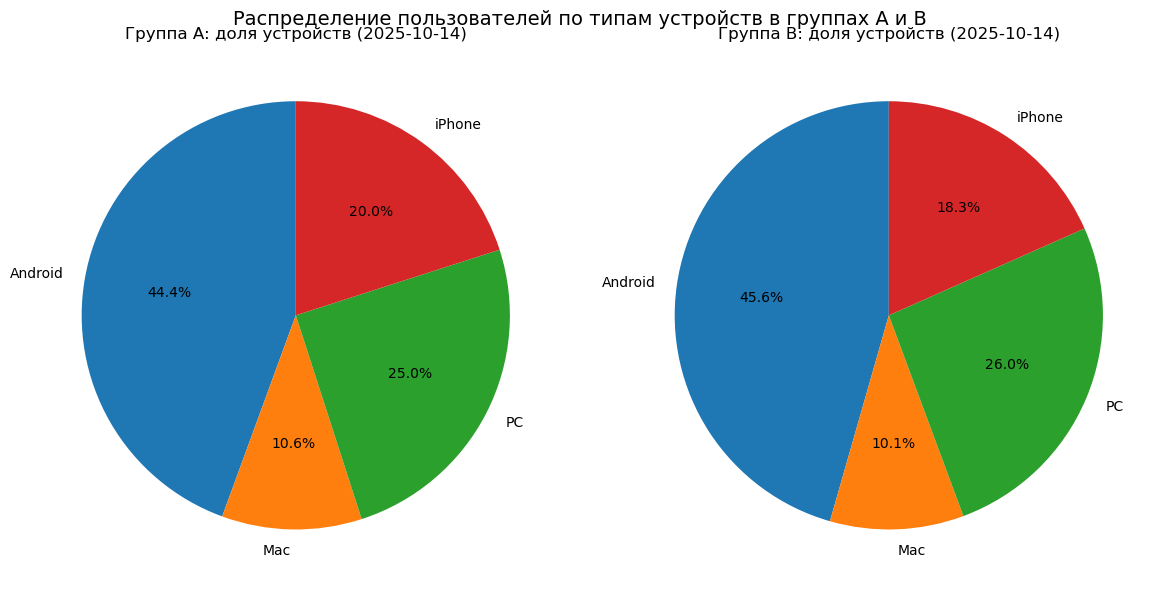

In [27]:
# Строим две диаграммы рядом
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].pie(
    device_share_a,
    labels=device_share_a.index,
    autopct='%1.1f%%',
    startangle=90
)
axes[0].set_title(f'Группа A: доля устройств ({test_date})')

axes[1].pie(
    device_share_b,
    labels=device_share_b.index,
    autopct='%1.1f%%',
    startangle=90
)
axes[1].set_title(f'Группа B: доля устройств ({test_date})')

fig.suptitle('Распределение пользователей по типам устройств в группах A и B', fontsize=14)
plt.tight_layout()
plt.show()

Распределение по типам устройств совпадает.

### 3.4. Равномерность распределения пользователей по регионам

Теперь убедитесь, что пользователи равномерно распределены по регионам.

In [28]:
# Считаем количество уникальных пользователей по региону в каждой группе
region_counts = (
    day_data
    .groupby(['test_group', 'region'])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

# Переводим в % внутри каждой группы
region_share_a = region_counts.loc['A'] / region_counts.loc['A'].sum() * 100
region_share_b = region_counts.loc['B'] / region_counts.loc['B'].sum() * 100

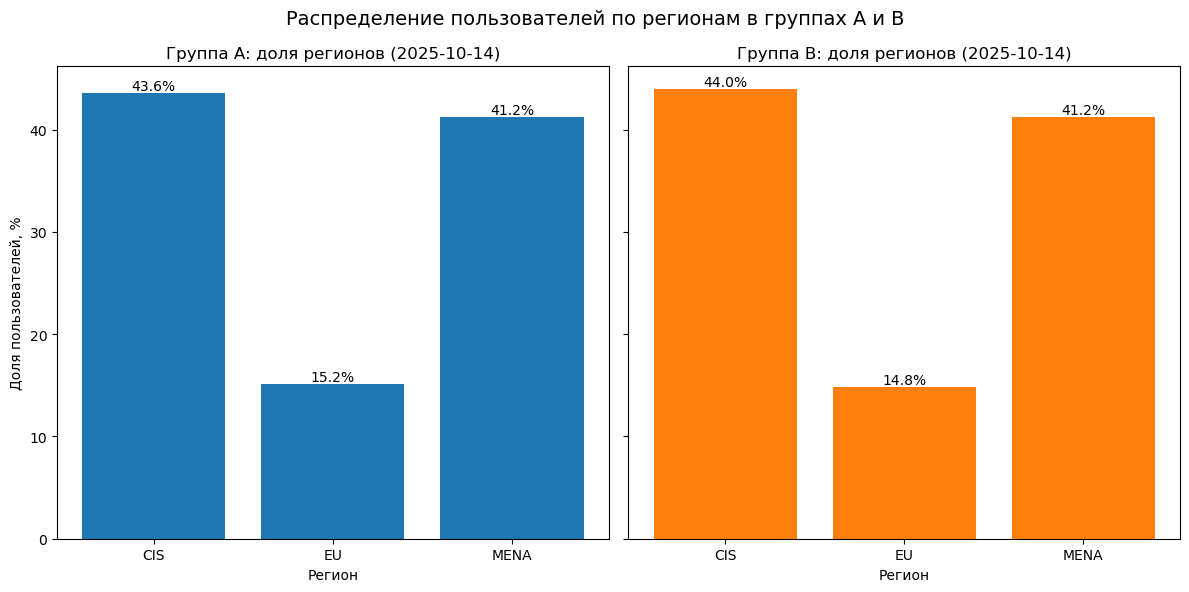

In [29]:
# Строим два столбчатых графика рядом
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

bars_a = axes[0].bar(region_share_a.index, region_share_a.values, color='tab:blue')
axes[0].set_title(f'Группа A: доля регионов ({test_date})')
axes[0].set_xlabel('Регион')
axes[0].set_ylabel('Доля пользователей, %')
for bar in bars_a:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, height,
                 f'{height:.1f}%', ha='center', va='bottom')

bars_b = axes[1].bar(region_share_b.index, region_share_b.values, color='tab:orange')
axes[1].set_title(f'Группа B: доля регионов ({test_date})')
axes[1].set_xlabel('Регион')
for bar in bars_b:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, height,
                 f'{height:.1f}%', ha='center', va='bottom')

fig.suptitle('Распределение пользователей по регионам в группах A и B', fontsize=14)
plt.tight_layout()
plt.show()

Здесь так же нет расхождений.

### 3.5. Вывод после проверки A/B-теста

Выводы на основе проверки:
- Количество уникальных пользователей в каждой из тестовых групп практически одинаково
- Пересекающихся пользователей в группах нет, следовательно выборки независимы
- Распределение пользователей по категориальным переменным (тип устройства и регион) совпадает в обеих группах
- A/B-тест проходит корректно, значимых нарушений не наблюдается

## 4. Проверка результатов A/B-теста

A/B-тест завершен, и у нас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

### 4.1. Формулировка нулевой и альтернативной гипотез. Определение целевой метрики

**Целевая метрика:** 
- Доля успешных первых сессий (page_counter >= 4) — она напрямую отражает уровень вовлеченности пользователя к контенту.

**Гипотеза H0**: 
- Новый алгоритм не влияет на долю успешных первых сессий (среднее значение метрики в группе B равно значению в группе A: μB = μA).

**Гипотеза H1**: 
- Новый алгоритм увеличивает долю успешных первых сессий (среднее значение в группе B статистически значимо выше, чем в группе A: μB > μA).

### 4.2. Получение результатов теста и подсчет основной метрики

In [30]:
# Загружаем датафрейм
sessions_test = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_test.csv')

In [31]:
# Создаем столбец good_session
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)

In [32]:
# Количество дней исследования
sessions_test['session_date'] = pd.to_datetime(sessions_test['session_date'])
sessions_test['session_date'].dt.date.nunique()

20

In [33]:
# Уникальные пользователи в каждой группе
sessions_test.groupby('test_group')['user_id'].nunique()

test_group
A    15163
B    15416
Name: user_id, dtype: int64

### 4.3. Сравнение доли успешных первых сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используем созданный на прошлом шаге столбец `good_session` и рассчитаем долю успешных первых сессий для выборок A и B, а также разницу в этом показателе.

In [34]:
# Оставляем только первые сессии пользователей
first_sessions = sessions_test[sessions_test['session_number'] == 1]

# Считаем долю успешных первых сессий по группам
good_session_share = first_sessions.groupby('test_group')['good_session'].mean() * 100

share_a = good_session_share['A']
share_b = good_session_share['B']
diff = share_b - share_a

print('Доля успешных первых сессий по группам:')
print(f'Группа A: {share_a:.2f}%')
print(f'Группа B: {share_b:.2f}%')
print(f'Разница (B - A): {diff:.2f} п.п.')

Доля успешных первых сессий по группам:
Группа A: 31.57%
Группа B: 31.47%
Разница (B - A): -0.11 п.п.


### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге мы убедились, что доли успешных первых сессий в тестовой и контрольной выборках близки, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

Так как `good_session` — бинарная метрика, а мы сравниваем доли между двумя независимыми группами, для проверки статистической значимости подходит **Z-тест пропорций**.

In [35]:
# Считаем количество "успехов" и общее количество наблюдений в каждой группе
successes = first_sessions.groupby('test_group')['good_session'].sum()
totals = first_sessions.groupby('test_group')['good_session'].count()

count = [successes['A'], successes['B']]
nobs = [totals['A'], totals['B']]

In [36]:
# Проводим z-тест для двух долей
z_stat, p_value = proportions_ztest(count, nobs)

alpha = 0.05

if p_value < alpha:
    print(f'p-value ({p_value:.4f}) < уровня значимости ({alpha}) — '
          f'различие между группами статистически значимо. '
          f'Отвергаем нулевую гипотезу о равенстве долей.')
else:
    print(f'p-value ({p_value:.4f}) >= уровня значимости ({alpha}) — '
          f'статистически значимого различия между группами не обнаружено. '
          f'Нет оснований отвергать нулевую гипотезу о равенстве долей.')

p-value (0.8433) >= уровня значимости (0.05) — статистически значимого различия между группами не обнаружено. Нет оснований отвергать нулевую гипотезу о равенстве долей.


### 4.5. Вывод по результатам A/B-эксперимента

На основе проведенного анализа результатов теста сформулируем выводы:
- Задействовано 30 579 пользователей
- Длительность эксперимента 20 дней
- Значение p-value по итогу эксперимента составило 0.8433
- Статистически значимого эффекта от внедрения нового алгоритма рекомендаций обнаружено не было - нововведение не следует выкатывать сейчас: нужно либо продлить тест, либо принять решение исходя из стоимости внедрения